# SwiGLU gate-sign regimes: double-negative echoes

A gated MLP neuron computes $\text{post} = \text{act}(\text{gate}) \cdot \text{value}$. With SiLU or GELU, $\text{act}(\text{gate})$ is a small negative number when the gate is closed, so a closed gate times a negative value gives a **positive** output. Goodfire's essay [*Neural Networks Are Already Clean*](https://already-clean.goodfire.com/) calls this the double-negative regime. It reports that the echo is usually small, but for about 4% of neurons it fills the whole top of the positive activation list. Max-activating-example dashboards then describe these neurons by their echo.

This notebook uses only existing `TransformerBridge` hook points to:

1. split every neuron's output by the signs of its two factors;
2. find neurons whose top activations are echoes, and compare the echo with the neuron's gate-open peak;
3. remove the echo with a forward hook and measure the loss change against two controls.

It runs SmolLM2-135M on CPU in float32 with a small token budget, so the saved outputs stay portable. Change `DEVICE` and the token budgets for real analyses. The last section lists full-size results for three models. Proposal: [#1933](https://github.com/TransformerLensOrg/TransformerLens/issues/1933).

In [1]:
# NBVAL_IGNORE_OUTPUT
import os

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import datasets
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F

from transformer_lens.model_bridge import TransformerBridge
from transformer_lens.utilities import SUPPORTED_ACTIVATIONS

datasets.disable_progress_bars()
torch.set_grad_enabled(False)
DEVICE = "cpu"
MODEL_NAME = "HuggingFaceTB/SmolLM2-135M"
SEQ_LEN = 256
SWEEP_TOKENS = 16_384  # the full-size runs below used ~262k
EVAL_TOKENS = 4_096  # the full-size runs below used 65k
TOP_K = 20
ECHO_DOMINATED = 0.9  # share of a neuron's top-k that must be echoes
SKIP = 1  # position 0 collects attention-sink activations; leave it out of every statistic

## The four sign regimes

| gate | value | act(gate) | post | regime |
| --- | --- | --- | --- | --- |
| > 0 | > 0 | positive | positive | open, positive pole |
| > 0 | < 0 | positive | negative | open, negative pole |
| < 0 | > 0 | small negative | negative | closed |
| < 0 | < 0 | small negative | **positive** | closed: the echo |

The echo is bounded by $|\min \text{act}| \cdot |\text{value}|$. The bound depends on the activation, so it is model-specific:

In [2]:
grid = torch.linspace(-10, 0, 1_000_001)
for name in ("silu", "gelu", "gelu_pytorch_tanh"):
    print(f"min {name:18s} = {SUPPORTED_ACTIVATIONS[name](grid).min().item():.3f}")

min silu               = -0.278
min gelu               = -0.170
min gelu_pytorch_tanh  = -0.170


## Load a raw Bridge

The hook aliases `mlp.hook_pre` (gate), `mlp.hook_pre_linear` (value) and `mlp.hook_post` (their product) exist on every gated MLP bridge, including fused gate/up projections (`JointGateUpMLPBridge`). The activation comes from the model config, and a factorization check confirms the hooks recompose the MLP exactly.

In [3]:
# NBVAL_IGNORE_OUTPUT
model = TransformerBridge.boot_transformers(MODEL_NAME, device=DEVICE, dtype=torch.float32).eval()

In [4]:
act = SUPPORTED_ACTIVATIONS[model.cfg.act_fn]
N_LAYERS, D_MLP = model.cfg.n_layers, model.cfg.d_mlp
print(f"{MODEL_NAME}: {N_LAYERS} layers x {D_MLP} neurons, act_fn={model.cfg.act_fn}")


def run_with_gated_mlp(model, tokens, on_layer):
    """Forward once, calling on_layer(layer, gate, value, post) as soon as each MLP finishes.

    Only one layer's factors are alive at a time, so memory does not grow with depth.
    """
    pending = {}

    def keep(key):
        def hook(tensor, hook):
            pending[key] = tensor

        return hook

    def finish(layer):
        def hook(tensor, hook):
            on_layer(layer, pending.pop(("gate", layer)), pending.pop(("value", layer)), tensor)

        return hook

    fwd_hooks = []
    for layer in range(model.cfg.n_layers):
        fwd_hooks += [
            (f"blocks.{layer}.mlp.hook_pre", keep(("gate", layer))),
            (f"blocks.{layer}.mlp.hook_pre_linear", keep(("value", layer))),
            (f"blocks.{layer}.mlp.hook_post", finish(layer)),
        ]
    with model.hooks(fwd_hooks=fwd_hooks):
        return model(tokens)


factor_error = []
run_with_gated_mlp(
    model,
    model.to_tokens("The quick brown fox jumps over the lazy dog."),
    lambda layer, gate, value, post: factor_error.append((post - act(gate) * value).abs().max()),
)
print(f"max |post - act(gate) * value| over all layers: {max(factor_error).item():.1e}")
assert max(factor_error) < 1e-6

HuggingFaceTB/SmolLM2-135M: 30 layers x 1536 neurons, act_fn=silu
max |post - act(gate) * value| over all layers: 0.0e+00


## Data

WikiText-2 at a pinned revision, tokenized as one stream and cut into fixed-length rows. Validation rows feed the sweep. Test rows feed the loss experiment, so the neurons are chosen and evaluated on different text.

In [5]:
# NBVAL_IGNORE_OUTPUT
WIKITEXT = ("Salesforce/wikitext", "wikitext-2-raw-v1")
WIKITEXT_REVISION = "b08601e04326c79dfdd32d625aee71d232d685c3"


def token_rows(split, n_tokens):
    text = "".join(
        datasets.load_dataset(*WIKITEXT, split=split, revision=WIKITEXT_REVISION)["text"]
    )
    ids = model.tokenizer(text, add_special_tokens=False, return_tensors="pt").input_ids[0]
    n_rows = n_tokens // SEQ_LEN
    return ids[: n_rows * SEQ_LEN].view(n_rows, SEQ_LEN)


sweep_rows = token_rows("validation", SWEEP_TOKENS)
eval_rows = token_rows("test", EVAL_TOKENS)

In [6]:
print(f"sweep rows {tuple(sweep_rows.shape)}, eval rows {tuple(eval_rows.shape)}")

sweep rows (64, 256), eval rows (16, 256)


## Sweep: per-neuron top-k, tagged by regime

One streaming pass keeps, for every neuron:

- its `TOP_K` largest outputs, each tagged as an echo or not;
- its `TOP_K` most negative outputs;
- its echo peak, the largest positive output with the gate closed;
- its gate-open peak, the largest $|\text{post}|$ with the gate open.

The top of the list is what a max-activating-example dashboard shows. Counting regimes over all tokens instead would mostly measure near-zero activations.

In [7]:
class Sweep:
    def __init__(self, n_layers, d_mlp, k):
        shape = (n_layers, d_mlp, k)
        self.top_val = torch.full(shape, -torch.inf)
        self.top_echo = torch.zeros(shape, dtype=torch.bool)
        self.top_loc = torch.zeros(shape, dtype=torch.long)
        self.bot_val = torch.full(shape, -torch.inf)  # negated, so topk finds the most negative
        self.bot_loc = torch.zeros(shape, dtype=torch.long)
        self.echo_peak = torch.zeros(n_layers, d_mlp)
        self.open_peak = torch.zeros(n_layers, d_mlp)

    @staticmethod
    def merge(old_val, new_val, *payloads):
        """Keep the k largest of old and new columns, carrying payloads along."""
        val = torch.cat([old_val, new_val], 1)
        best = val.topk(old_val.shape[1], dim=1).indices
        return (val.gather(1, best),) + tuple(torch.cat(p, 1).gather(1, best) for p in payloads)

    def update(self, layer, gate, post, row_offset):
        gate, post = gate[:, SKIP:], post[:, SKIP:]
        rows, positions, d = post.shape
        loc = (row_offset + torch.arange(rows))[:, None] * SEQ_LEN + SKIP + torch.arange(positions)
        gate, post, loc = gate.reshape(-1, d), post.reshape(-1, d), loc.reshape(-1)
        closed = gate < 0
        echo = closed & (post > 0)
        k = self.top_val.shape[-1]

        val, idx = post.topk(k, dim=0)
        self.top_val[layer], self.top_echo[layer], self.top_loc[layer] = self.merge(
            self.top_val[layer],
            val.T,
            (self.top_echo[layer], echo.gather(0, idx).T),
            (self.top_loc[layer], loc[idx].T),
        )
        val, idx = (-post).topk(k, dim=0)
        self.bot_val[layer], self.bot_loc[layer] = self.merge(
            self.bot_val[layer], val.T, (self.bot_loc[layer], loc[idx].T)
        )
        self.echo_peak[layer] = self.echo_peak[layer].maximum(post.masked_fill(~echo, 0).amax(0))
        self.open_peak[layer] = self.open_peak[layer].maximum(
            post.abs().masked_fill(closed, 0).amax(0)
        )


BATCH = 8
sweep = Sweep(N_LAYERS, D_MLP, TOP_K)
for start in range(0, len(sweep_rows), BATCH):
    run_with_gated_mlp(
        model,
        sweep_rows[start : start + BATCH].to(DEVICE),
        lambda layer, gate, value, post: sweep.update(layer, gate.cpu(), post.cpu(), start),
    )

leak_frac = sweep.top_echo.float().mean(-1)  # share of each neuron's top-k that are echoes
echo_dominated = leak_frac >= ECHO_DOMINATED
print(f"tokens per neuron: {len(sweep_rows) * (SEQ_LEN - SKIP):,}")
print(
    f"echo-dominated neurons (>= {ECHO_DOMINATED:.0%} of top-{TOP_K} are echoes): "
    f"{echo_dominated.float().mean():.1%} of {echo_dominated.numel():,}"
)
print(f"top-{TOP_K} entirely echoes: {(leak_frac == 1).float().mean():.1%}")
print(f"at least one echo in the top-{TOP_K}: {(leak_frac > 0).float().mean():.1%}")

tokens per neuron: 16,320
echo-dominated neurons (>= 90% of top-20 are echoes): 3.6% of 46,080
top-20 entirely echoes: 2.0%
at least one echo in the top-20: 21.9%


Fewer tokens make every top-k less extreme, so these shares come out higher than in a large sweep. In the full SmolLM2 run (264k tokens per neuron), 1.3% of neurons were echo-dominated. Echo-dominated neurons cluster in the middle layers:

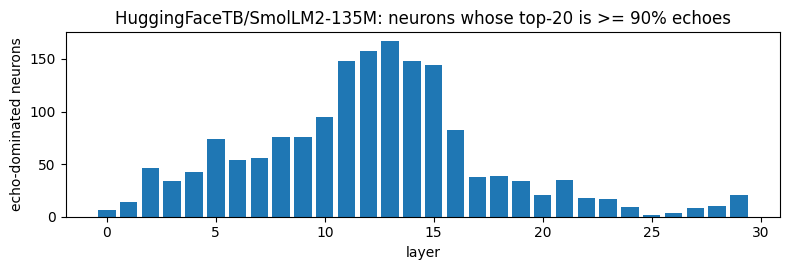

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(range(N_LAYERS), echo_dominated.sum(1))
ax.set_xlabel("layer")
ax.set_ylabel("echo-dominated neurons")
ax.set_title(f"{MODEL_NAME}: neurons whose top-{TOP_K} is >= {ECHO_DOMINATED:.0%} echoes")
plt.tight_layout()
plt.show()

## One echo-dominated neuron

The neuron below is chosen by rule as a typical case. Among neurons whose whole top-k is echoes, it has the echo-to-gate-open-peak ratio closest to the median (the next section looks at that ratio). Its positive list is what a dashboard would label it by. `[[ ]]` marks the token where each activation occurs.

In [9]:
flat_sweep = sweep_rows.reshape(-1)


def context(loc, left=12, right=4):
    row_start = loc - loc % SEQ_LEN
    pre = model.tokenizer.decode(flat_sweep[max(row_start, loc - left) : loc])
    token = model.tokenizer.decode(flat_sweep[loc : loc + 1])
    post = model.tokenizer.decode(flat_sweep[loc + 1 : min(row_start + SEQ_LEN, loc + 1 + right)])
    return (pre + "[[" + token + "]]" + post).replace("\n", " ")


all_echo = (leak_frac == 1) & (sweep.open_peak > 0)
peak_ratio = sweep.echo_peak / sweep.open_peak.clamp_min(1e-12)
typical = peak_ratio[all_echo].median()
layer, neuron = divmod(
    int(((peak_ratio - typical).abs() + (~all_echo) * torch.inf).argmin()), D_MLP
)
print(
    f"layer {layer}, neuron {neuron}: echo peak {sweep.echo_peak[layer, neuron]:.2f}, "
    f"gate-open peak {sweep.open_peak[layer, neuron]:.2f}"
)
rows = [
    {
        "pole": "top positive",
        "post": round(float(v), 2),
        "echo": bool(e),
        "context": context(int(l)),
    }
    for v, e, l in zip(
        sweep.top_val[layer, neuron][:5],
        sweep.top_echo[layer, neuron][:5],
        sweep.top_loc[layer, neuron][:5],
    )
] + [
    {
        "pole": "most negative",
        "post": round(-float(v), 2),
        "echo": False,
        "context": context(int(l)),
    }
    for v, l in zip(sweep.bot_val[layer, neuron][:5], sweep.bot_loc[layer, neuron][:5])
]
with pd.option_context("display.max_colwidth", 100):
    display(pd.DataFrame(rows))

layer 0, neuron 228: echo peak 0.47, gate-open peak 1.39


,pole,post,echo,context
0,top positive,0.47,True,it was listed as a Mississippi Landmark . The E.[[F]]. Young Hotel was
1,top positive,0.38,True,44 trains coming in and out daily . The city '[[s]] economy not only depended
2,top positive,0.37,True,"18th and 19th Aves , [[5]]th St , and"
3,top positive,0.37,True,"be successful in life . When designing Shikamaru '[[s]] Part II appearance ,"
4,top positive,0.37,True,"year . In 2009 , the department '[[s]] measurements indicated that a"
5,most negative,-1.39,False,"Meridian Transit System , Greyhound Buses , and Trail[[ways]] , averaging 2"
6,most negative,-1.24,False,rerouted to follow the US 131 free[[way]] south of Howard City
7,most negative,-1.16,False,3 as a WPA project . After a brief slow[[down]] of the economy at
8,most negative,-1.11,False,"62 , he was posted to RAAF Base Butter[[worth]] , Malaya ,"
9,most negative,-1.08,False,Two weeks later he married Katherine Bridge at St Paul 's[[ Anglican]] Church in Frankston


The echoes share no obvious pattern: a letter in an abbreviation, a possessive *s*, a street number. The gate-open negative pole is about three times larger and reads as one pattern: the second piece of a compound word (*Trail-ways*, *free-way*, *slow-down*). Labeling this neuron from its top positive examples would describe its echo.

## How large is the echo?

For each echo-dominated neuron, divide its echo peak by its gate-open peak. The essay's worked example (Qwen3-32B L1/N20736) sits under 0.08. Neurons whose gate never opened have no gate-open peak, so they are counted separately.

echo / gate-open peak over echo-dominated neurons: p25 0.26, median 0.47, p75 0.88
share under 0.08: 3%
echo-dominated neurons whose gate never opened: 17


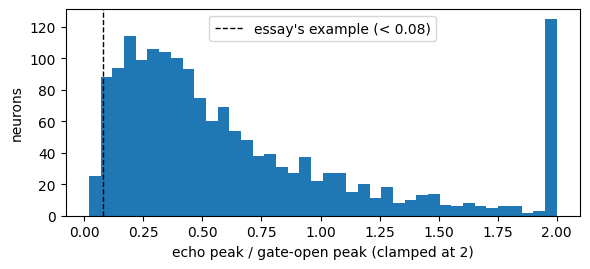

In [10]:
gate_opens = sweep.open_peak > 1e-3 * sweep.echo_peak
ratio = (sweep.echo_peak / sweep.open_peak)[echo_dominated & gate_opens]
q25, q50, q75 = ratio.quantile(torch.tensor([0.25, 0.5, 0.75])).tolist()
print(
    f"echo / gate-open peak over echo-dominated neurons: p25 {q25:.2f}, median {q50:.2f}, p75 {q75:.2f}"
)
print(f"share under 0.08: {(ratio < 0.08).float().mean():.0%}")
print(
    f"echo-dominated neurons whose gate never opened: {int((echo_dominated & ~gate_opens).sum())}"
)

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(ratio.clamp(max=2).numpy(), bins=40)
ax.axvline(0.08, color="black", linestyle="--", linewidth=1, label="essay's example (< 0.08)")
ax.legend()
ax.set_xlabel("echo peak / gate-open peak (clamped at 2)")
ax.set_ylabel("neurons")
plt.tight_layout()
plt.show()

For most echo-dominated neurons the echo is a sizeable fraction of the gate-open peak, and the bar at 2 collects neurons whose echo is more than twice their gate-open peak.

## Does the model use the echo?

`remove_closed_hooks` zeroes a neuron's output wherever its gate is closed and the output has the chosen sign. Removing the positive sign removes the echo. Each condition is compared with the unmodified model's next-token loss on the held-out test rows:

- **echo, all neurons**: the essay's network-wide ablation, as we read it;
- **closed negatives, all neurons**: a control with the same gate state and the opposite sign, which asks whether the whole closed regime carries signal;
- **echo, echo-dominated neurons**: only the neurons the sweep selected;
- **echo, random neurons**: the same number of neurons per layer, drawn at random from the rest, which checks whether the selection matters.

In [11]:
def remove_closed_hooks(neurons, sign):
    """Hooks that zero post where the gate is closed and post has the given sign.

    `neurons` is a [layer, neuron] mask; sign +1 removes the echo, -1 the closed negatives.
    """
    gates, fwd_hooks = {}, []
    for layer in range(N_LAYERS):
        mask = neurons[layer].to(DEVICE)
        if not mask.any():
            continue

        def keep_gate(tensor, hook, layer=layer):
            gates[layer] = tensor

        def edit(tensor, hook, layer=layer, mask=mask):
            closed = gates.pop(layer) < 0
            return tensor.masked_fill(closed & (tensor * sign > 0) & mask, 0)

        fwd_hooks += [
            (f"blocks.{layer}.mlp.hook_pre", keep_gate),
            (f"blocks.{layer}.mlp.hook_post", edit),
        ]
    return fwd_hooks


def mean_loss(fwd_hooks):
    total, count = 0.0, 0
    with model.hooks(fwd_hooks=fwd_hooks):
        for start in range(0, len(eval_rows), BATCH):
            tokens = eval_rows[start : start + BATCH].to(DEVICE)
            logits = model(tokens)
            nll = F.cross_entropy(
                logits[:, SKIP:-1].flatten(0, 1).float(),
                tokens[:, SKIP + 1 :].flatten(),
                reduction="sum",
            )
            total, count = total + nll.item(), count + tokens[:, SKIP + 1 :].numel()
    return total / count


generator = torch.Generator().manual_seed(0)
random_neurons = torch.zeros_like(echo_dominated)
for layer in range(N_LAYERS):
    pool = (~echo_dominated[layer]).nonzero().squeeze(-1)
    n = int(echo_dominated[layer].sum())
    random_neurons[layer, pool[torch.randperm(len(pool), generator=generator)[:n]]] = True

everyone = torch.ones_like(echo_dominated)
conditions = {
    "echo, all neurons": remove_closed_hooks(everyone, +1),
    "closed negatives, all neurons": remove_closed_hooks(everyone, -1),
    "echo, echo-dominated neurons": remove_closed_hooks(echo_dominated, +1),
    "echo, random neurons": remove_closed_hooks(random_neurons, +1),
}
baseline = mean_loss([])
print(f"baseline loss: {baseline:.3f} over {len(eval_rows) * (SEQ_LEN - SKIP - 1):,} predictions")
pd.DataFrame(
    [
        {"removed": name, "Δ loss": round(mean_loss(hooks) - baseline, 3)}
        for name, hooks in conditions.items()
    ]
)

baseline loss: 3.227 over 4,064 predictions


,removed,Δ loss
0,"echo, all neurons",1.414
1,"closed negatives, all neurons",0.843
2,"echo, echo-dominated neurons",0.334
3,"echo, random neurons",0.010


Removing the echo raises loss, both network-wide and from the selected neurons alone, and the random control barely moves. At this size, the model uses its closed-gate outputs.

## Full-size results

The same procedure with larger budgets: 261k–264k validation tokens per neuron, and 65,024 held-out test predictions. SmolLM2-135M and Qwen3-0.6B ran in float32 and Qwen3-1.7B in bfloat16. Δ loss is in nats per token.

| | SmolLM2-135M | Qwen3-0.6B | Qwen3-1.7B |
| --- | ---: | ---: | ---: |
| Neurons whose top-20 is ≥ 90% echo | 1.32% | 2.90% | 2.84% |
| Echo / gate-open peak (median, those neurons) | 0.343 | 0.448 | 0.415 |
| Δ loss, echo removed, all neurons | +1.45 | +2.09 | +1.62 |
| Δ loss, closed negatives removed, all neurons | +0.90 | +2.34 | +1.89 |
| Δ loss, echo removed, echo-dominated neurons | +0.21 | +1.31 | +0.53 |
| Δ loss, echo removed, random neurons | +0.002 | +0.049 | +0.039 |

In the Qwen3 models, layer 1 holds many echo-dominated neurons, and some neurons never open their gate. Splitting the echo-dominated set shows the removal cost does not come from either group. Each cell gives Δ loss, then the same-size random control in parentheses, then the number of neurons. The first two groups overlap (layer 1 contains some never-open neurons), and "Neither" excludes both:

| | SmolLM2-135M | Qwen3-0.6B | Qwen3-1.7B |
| --- | ---: | ---: | ---: |
| Layer 1 | +0.006 (+0.000) · 7 | +0.088 (−0.005) · 542 | +0.040 (+0.028) · 1,983 |
| Gate never opens | +0.003 (+0.000) · 2 | +0.366 (+0.001) · 108 | +0.036 (+0.008) · 610 |
| Neither | +0.180 (+0.006) · 597 | +0.257 (+0.001) · 1,899 | +0.259 (+0.007) · 2,830 |

## Reading the results

- **The echo distorts labels.** A neuron whose top-k is all echoes is described by its echo. Before labeling a neuron from its max-activating examples, tag the regime, and read the gate-open negative pole.
- **"Small" is model-specific.** Here the echo is a third to a half of the gate-open peak, far above the essay's example. Check the ratio on your model before treating the echo as noise.
- **Removal is not free at these sizes.** The essay reports that network-wide ablation raised most benchmarks but lowered some reasoning ones, on much larger models. Within Qwen3 the cost falls from 0.6B to 1.7B, but two sizes are not a trend.
- **Effects are not additive.** In Qwen3-0.6B the three groups cost about 0.71 nats separately but 1.31 together, so report exactly which neurons were edited.
- **Budgets matter.** Top-k shares fall as the sweep grows, so compare models at matched token counts.